# 04 — Generate and Evaluate Answers

This notebook generates answers for all (question × strategy) pairs with `gpt-4o-mini`, then runs an LLM-as-judge evaluation (`gpt-4o-mini`, temperature 0) against **reference answers** and the **chunks each strategy actually retrieved**, and classifies any errors.

> Reference answers come from `src/reference_answers.py` (XBRL facts + gold filing sections, written by gpt-4o). Build and review them before running section 4.4.

**Pipeline:**
1. Load retrieval results from notebook 03
2. For each (question_id, strategy), call `generation.generate_answer()` with the retrieved chunks as context
3. Parse the structured JSON response (answer, citations, confidence, evidence_used)
4. Run `evaluation.evaluate_answer()` to score on 3 dimensions (0–2 each)
5. Run `evaluation.classify_error()` to assign an error type and stage
6. Save to `data/processed/evaluation_results.csv`

**Cost estimate:** ~120 generation calls + 120 evaluation calls ≈ ~$0.10–0.20 with gpt-4o-mini.

**Runtime:** ~15–25 minutes.

In [1]:
import sys
sys.path.insert(0, '..')

import os
import json
import pandas as pd

from src.config import PROCESSED_DIR
from src.generation import generate_answer, run_experiment
from src.evaluation import evaluate_answer, classify_error, run_full_evaluation
from src.error_taxonomy import ERROR_TYPES

questions_df = pd.read_csv(os.path.join(PROCESSED_DIR, 'questions.csv'))
retrieval_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'retrieval_results.parquet'))

print(f"Questions: {len(questions_df)}")
print(f"Retrieval rows: {len(retrieval_df)}")
print(f"Strategies: {retrieval_df['strategy'].unique()}")

Questions: 40
Retrieval rows: 580
Strategies: ['vanilla' 'metadata_filtered' 'task_aware']


## 4.1 — Single answer demo

Test the generation pipeline on one question before running the full batch.

In [2]:
demo_q = questions_df[questions_df['task_type'] == 'single_fact'].iloc[0]
question_id = demo_q['question_id']
question = demo_q['question']

demo_chunks = retrieval_df[
    (retrieval_df['question_id'] == question_id) &
    (retrieval_df['strategy'] == 'metadata_filtered')
].sort_values('rank').to_dict('records')

print(f"Question: {question}")
print(f"Retrieved {len(demo_chunks)} chunks")

result = generate_answer(question, demo_chunks)

print("\n--- Answer ---")
print(result['answer'])
print(f"\nConfidence: {result['confidence']}")
print(f"Evidence used: {result['evidence_used']}")
print(f"Citations: {json.dumps(result['citations'], indent=2)}")

Question: What was Apple's total net revenue for fiscal year 2023?
Retrieved 5 chunks



--- Answer ---
Apple's total net revenue for fiscal year 2023 was $383.285 billion.

Confidence: high
Evidence used: The evidence from both the MD&A and the financial statements states that total net sales for 2023 were $383.285 billion, confirming the total revenue figure directly.
Citations: [
  {
    "chunk_id": "AAPL_2023_md_a_0001",
    "ticker": "AAPL",
    "year": 2023,
    "section": "MD&A"
  },
  {
    "chunk_id": "AAPL_2023_financial_statements_0005",
    "ticker": "AAPL",
    "year": 2023,
    "section": "Financial Statements"
  }
]


## 4.2 — Run full generation experiment

In [3]:
gen_results_path = os.path.join(PROCESSED_DIR, 'generation_results.csv')

if os.path.exists(gen_results_path):
    print(f"Loading existing generation results from {gen_results_path}")
    gen_df = pd.read_csv(gen_results_path)
else:
    print("Running generation experiment (this will call the OpenAI API)...")
    gen_df = run_experiment(questions_df, retrieval_df)
    gen_df.to_csv(gen_results_path, index=False)
    print(f"Saved to {gen_results_path}")

print(f"\nGeneration results shape: {gen_df.shape}")
print(f"Errors: {gen_df['error'].notna().sum()} / {len(gen_df)}")
gen_df.head(3)

Running generation experiment (this will call the OpenAI API)...


Generating answers:   0%|          | 0/40 [00:00<?, ?it/s]

Generating answers:   2%|▎         | 1/40 [00:06<04:27,  6.85s/it]

Generating answers:   5%|▌         | 2/40 [00:12<04:04,  6.43s/it]

Generating answers:   8%|▊         | 3/40 [00:18<03:48,  6.17s/it]

...

Generating answers:  98%|█████████▊| 39/40 [05:52<00:09,  9.39s/it]

Generating answers: 100%|██████████| 40/40 [06:01<00:00,  9.48s/it]

Generating answers: 100%|██████████| 40/40 [06:01<00:00,  9.04s/it]

Saved to /Users/xieweixun/Desktop/projects/sec-rag-failure-modes/notebooks/../src/../data/processed/generation_results.csv

Generation results shape: (120, 8)
Errors: 0 / 120


,question_id,strategy,answer,citations_json,confidence,evidence_used,raw_response,error
0,Q001,vanilla,Apple's total net revenue for fiscal year 2023...,"[{""chunk_id"": ""AAPL_2023_md_a_0001"", ""ticker"":...",high,The total net sales for Apple in fiscal year 2...,"{\n ""answer"": ""Apple's total net revenue for ...",None
1,Q001,metadata_filtered,Apple's total net revenue for fiscal year 2023...,"[{""chunk_id"": ""AAPL_2023_md_a_0001"", ""ticker"":...",high,The total net sales reported for Apple in 2023...,"{\n ""answer"": ""Apple's total net revenue for ...",None
2,Q001,task_aware,Apple's total net revenue for fiscal year 2023...,"[{""chunk_id"": ""AAPL_2023_md_a_0001"", ""ticker"":...",high,The total net sales for Apple in fiscal year 2...,"{\n ""answer"": ""Apple's total net revenue for ...",None


## 4.3 — Confidence distribution

Check the model's self-reported confidence before running evaluation.

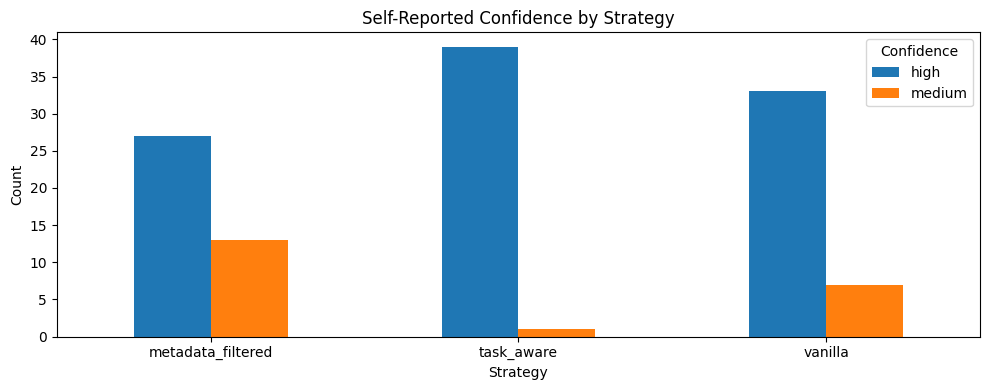

In [4]:
import matplotlib.pyplot as plt

conf_pivot = gen_df.groupby(['strategy', 'confidence']).size().unstack(fill_value=0)
conf_pivot.plot(kind='bar', figsize=(10, 4), rot=0)
plt.title('Self-Reported Confidence by Strategy')
plt.xlabel('Strategy')
plt.ylabel('Count')
plt.legend(title='Confidence')
plt.tight_layout()
plt.show()

## 4.4 — Run full evaluation (LLM-as-judge)

In [5]:
eval_results_path = os.path.join(PROCESSED_DIR, 'evaluation_results.csv')

if os.path.exists(eval_results_path):
    print(f"Loading existing evaluation results from {eval_results_path}")
    eval_df = pd.read_csv(eval_results_path)
else:
    print("Running LLM-as-judge evaluation...")
    from src.reference_answers import build_reference_answers, attach_reference_answers
    build_reference_answers()                      # no-op if reference_answers.csv already exists
    questions_df = attach_reference_answers()
    eval_df = run_full_evaluation(gen_df, questions_df, retrieval_df)

print(f"\nEvaluation results shape: {eval_df.shape}")
print(f"\nMean scores by strategy:")
print(eval_df.groupby('strategy')[['answer_correctness', 'citation_faithfulness', 'evidence_coverage']].mean().round(2))

Running LLM-as-judge evaluation...
Reference answers already exist at /Users/xieweixun/Desktop/projects/sec-rag-failure-modes/notebooks/../src/../data/processed/reference_answers.csv (pass overwrite=True to rebuild)
questions.csv now has expected_answer for 40/40 questions


Evaluating answers:   0%|          | 0/120 [00:00<?, ?it/s]

Evaluating answers:   1%|          | 1/120 [00:01<03:52,  1.96s/it]

Evaluating answers:   2%|▏         | 2/120 [00:03<03:18,  1.69s/it]

Evaluating answers:   2%|▎         | 3/120 [00:04<03:02,  1.56s/it]

...

Evaluating answers:  98%|█████████▊| 118/120 [03:29<00:03,  1.66s/it]

Evaluating answers:  99%|█████████▉| 119/120 [03:30<00:01,  1.64s/it]

Evaluating answers: 100%|██████████| 120/120 [03:32<00:00,  1.72s/it]

Evaluating answers: 100%|██████████| 120/120 [03:32<00:00,  1.77s/it]


Evaluation results saved to /Users/xieweixun/Desktop/projects/sec-rag-failure-modes/notebooks/../src/../data/processed/evaluation_results.csv

Evaluation results shape: (120, 17)

Mean scores by strategy:
                   answer_correctness  citation_faithfulness  \
strategy                                                       
metadata_filtered                1.27                   1.10   
task_aware                       1.48                   1.27   
vanilla                          1.38                   1.23   

                   evidence_coverage  
strategy                              
metadata_filtered               1.23  
task_aware                      1.30  
vanilla                         1.27  


## 4.5 — Error distribution preview

In [6]:
print("Error type distribution:")
print(eval_df['error_type'].value_counts())

print("\nError stage distribution:")
print(eval_df['error_stage'].value_counts())

print("\nError stage by strategy:")
print(eval_df.groupby(['strategy', 'error_stage']).size().unstack(fill_value=0))

Error type distribution:
error_type
CORRECT                 46
REASONING_ERROR         38
WRONG_ENTITY            16
WRONG_YEAR              12
CITATION_FABRICATION     5
INCOMPLETE_SYNTHESIS     3
Name: count, dtype: int64

Error stage distribution:
error_stage
none          46
generation    46
retrieval     28
Name: count, dtype: int64

Error stage by strategy:
error_stage        generation  none  retrieval
strategy                                      
metadata_filtered           8    12         20
task_aware                 22    18          0
vanilla                    16    16          8
